# 04 — Reproducible assembled-state checkpoints

**Question.** Can a naturally assembled social state be saved, reconstructed exactly, and used as the same starting point for future paired experiments?

This is a protocol check, not a change to social behaviour. All candidate states come from the 30 random-start reference runs in notebook 01. A candidate is saved at the **first chronological confirmation** of one connected component continuously for at least five simulated seconds. We validate every eligible seed rather than selecting visually attractive trajectories or states that later perform well. The confirmation time is five seconds after the episode onset; a state cannot be selected prospectively using an onset that has not yet been confirmed.

Only constant-speed social dynamics are used here. No light condition exists.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_two"
STUDY_DIR = HERE

import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from handlings.trial_two.study_support import (
    checkpoint_payload, load_checkpoint, continuation_digest,
)
from handlings.trial_one.diagnostics import graph_components

DATA_DIR, FIGURE_DIR = STUDY_DIR / "data", STUDY_DIR / "figures"
CANDIDATE_DIR = DATA_DIR / "assembly_candidates"
CHECKPOINT_DIR = DATA_DIR / "assembled_checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

assembly = pd.read_csv(DATA_DIR / "01_long_horizon_summary.csv")
definition_decision = json.loads((DATA_DIR / "03_assembly_definition.json").read_text())
assert definition_decision["preferred_definition"] == "B"
assert definition_decision["B_supported_in_tested_cohort"]
display(definition_decision)
expected_seeds = set(assembly.loc[assembly.AssemblySuccess, "Seed"].astype(int))
candidates = sorted(CANDIDATE_DIR.glob("seed_*.json"), key=lambda p: int(p.stem.split("_")[-1]))
assert {int(p.stem.split("_")[-1]) for p in candidates} == expected_seeds
assert len(assembly) >= 30
print(f"Validating all {len(candidates)} first-confirmation candidates from {len(assembly)} random-start seeds.")

{'preferred_definition': 'B',
 'connectivity_radius_BL': 5.5,
 'required_number_of_components': 1,
 'persistence_s': 5.0,
 'monitor_every_internal_update': True,
 'assembly_time_means': 'first observed time of the first episode that later meets persistence',
 'checkpoint_time_means': 'first confirmation, onset + persistence',
 'biological_constant': False,
 'n_seeds': 30,
 'duration_s': 180.0,
 'A_B_success_disagreements': 0,
 'A_B_onset_disagreements_among_both_successful': 0,
 'B_C_success_disagreements': 0,
 'B_C_onset_disagreements_among_both_successful': 5,
 'B_successes': 30,
 'B_runs_with_later_breakup': 0,
 'B_supported_in_tested_cohort': True,
 'limitation': 'Finite seeds and horizon; sampled graph connectivity is not biological school validation.'}

Validating all 30 first-confirmation candidates from 30 random-start seeds.


## What is saved and what is tested

Each JSON file contains seed, absolute simulation step/time, fish IDs, positions, headings, individual speeds, all model parameters including `dt` and recording stride, and the NumPy and Python random-generator states. JSON stores floating-point values at round-trip precision. RNG states are included even though the reference rule currently uses no ongoing social noise; a stochastic continuation needs them.

The source run also saved a SHA-256 digest of its next 16 internal states after the checkpoint (or all available remaining steps if fewer). This lets us compare a restored continuation against the **original source trajectory**, rather than merely comparing two reconstructions that could share the same error. Positions, headings, speeds and the absolute step enter the digest at each update.

For every candidate we test:

1. Exact round-trip equality of state, parameters, both RNG states, agent IDs and state hash.
2. Agreement with the source trajectory's continuation digest.
3. Equality of two independently loaded constant-speed branches for 64 internal updates, checking every internal state through their full trajectory digest.
4. One connected component at the saved confirmation time and agreement of saved time with the assembly summary.

Previous DataCollector history is deliberately not restored. A fresh collector starts at the saved absolute step; its records describe the new branch. This changes observations, not the physical state, RNG sequence or update schedule.

In [2]:
def canonical_json(value):
    # JSON normalizes Python tuples to arrays in the source RNG state.
    return json.dumps(value, sort_keys=True, separators=(",", ":"))

validation_rows = []
for candidate in candidates:
    payload = json.loads(candidate.read_text())
    seed = int(payload["seed"])
    source_row = assembly.loc[assembly.Seed.eq(seed)].iloc[0]
    restored = load_checkpoint(payload)
    roundtrip = checkpoint_payload(restored)
    expected_base = {key: payload[key] for key in roundtrip}
    exact_roundtrip = canonical_json(roundtrip) == canonical_json(expected_base)
    assert exact_roundtrip, f"State/parameter/RNG round trip failed for seed {seed}."
    assert len(graph_components(np.asarray(payload["positions"]), restored.attraction_radius)) == 1
    assert payload["time"] == float(source_row.AssemblyConfirmedTime)
    assert payload["assembly_onset"] == float(source_row.AssemblyTime)
    assert np.isclose(payload["time"] - payload["assembly_onset"], 5.0, atol=1e-12)
    assert restored.steps == payload["step"]
    assert restored.recorded_steps == [payload["step"]]

    validation = payload["continuation_validation"]
    original_steps = int(validation["steps"])
    assert original_steps > 0, "A source-continuation check requires at least one following state."
    restored_digest = continuation_digest(restored, original_steps)
    exact_original = restored_digest == validation["sha256"]
    assert exact_original, f"Original continuation failed for seed {seed}."

    branch_a, branch_b = load_checkpoint(payload), load_checkpoint(payload)
    paired_steps = 64
    paired_a = continuation_digest(branch_a, paired_steps)
    paired_b = continuation_digest(branch_b, paired_steps)
    exact_paired = paired_a == paired_b
    assert exact_paired, f"Paired constant-speed controls failed for seed {seed}."
    # The collector begins at the checkpoint rather than reproducing pre-checkpoint history.
    pd.testing.assert_frame_equal(branch_a.datacollector.get_model_vars_dataframe(),
                                  branch_b.datacollector.get_model_vars_dataframe())
    pd.testing.assert_frame_equal(branch_a.datacollector.get_agent_vars_dataframe(),
                                  branch_b.datacollector.get_agent_vars_dataframe())

    payload["checkpoint_validation"] = {
        "state_roundtrip_exact": exact_roundtrip, "original_continuation_exact": exact_original,
        "original_continuation_steps": original_steps,
        "paired_constant_control_steps": paired_steps, "paired_controls_exact": exact_paired,
        "saved_at_first_persistent_confirmation": True, "light_implemented": False,
    }
    destination = CHECKPOINT_DIR / candidate.name
    destination.write_text(json.dumps(payload, indent=2, sort_keys=True) + "\n")
    validation_rows.append({
        "Seed": seed, "AssemblyOnset_s": payload["assembly_onset"],
        "CheckpointTime_s": payload["time"], "AbsoluteStep": payload["step"],
        "dt": payload["model_parameters"]["dt"],
        "RecordingInterval_s": restored.record_every * restored.dt,
        "StateRoundTripExact": exact_roundtrip, "OriginalContinuationSteps": original_steps,
        "OriginalContinuationExact": exact_original, "PairedControlUpdates": paired_steps,
        "PairedControlsExact": exact_paired, "StateSHA256": payload["state_sha256"],
        "CheckpointSHA256": hashlib.sha256(destination.read_bytes()).hexdigest(),
        "CheckpointFile": str(destination.relative_to(STUDY_DIR)),
    })

checkpoint_validation = pd.DataFrame(validation_rows)
assert len(checkpoint_validation) == len(expected_seeds)
checkpoint_validation.to_csv(DATA_DIR / "04_checkpoint_validation.csv", index=False)
display(checkpoint_validation.drop(columns=["StateSHA256", "CheckpointSHA256"]).round(3))
print(f"All {len(checkpoint_validation)} checkpoints passed every exact-state and continuation check.")
print("Source-continuation checks with fewer than 16 updates:",
      checkpoint_validation.loc[checkpoint_validation.OriginalContinuationSteps.lt(16), "Seed"].tolist())

,Seed,AssemblyOnset_s,CheckpointTime_s,AbsoluteStep,dt,RecordingInterval_s,StateRoundTripExact,OriginalContinuationSteps,OriginalContinuationExact,PairedControlUpdates,PairedControlsExact,CheckpointFile
0,0,86.750,91.750,734,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_0.json
1,1,0.000,5.000,40,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_1.json
2,2,73.875,78.875,631,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_2.json
3,3,14.250,19.250,154,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_3.json
4,4,47.000,52.000,416,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_4.json
5,5,12.500,17.500,140,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_5.json
6,6,21.250,26.250,210,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_6.json
7,7,7.625,12.625,101,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_7.json
8,8,14.125,19.125,153,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_8.json
9,9,56.000,61.000,488,0.125,1.0,True,16,True,64,True,data/assembled_checkpoints/seed_9.json


All 30 checkpoints passed every exact-state and continuation check.
Source-continuation checks with fewer than 16 updates: []


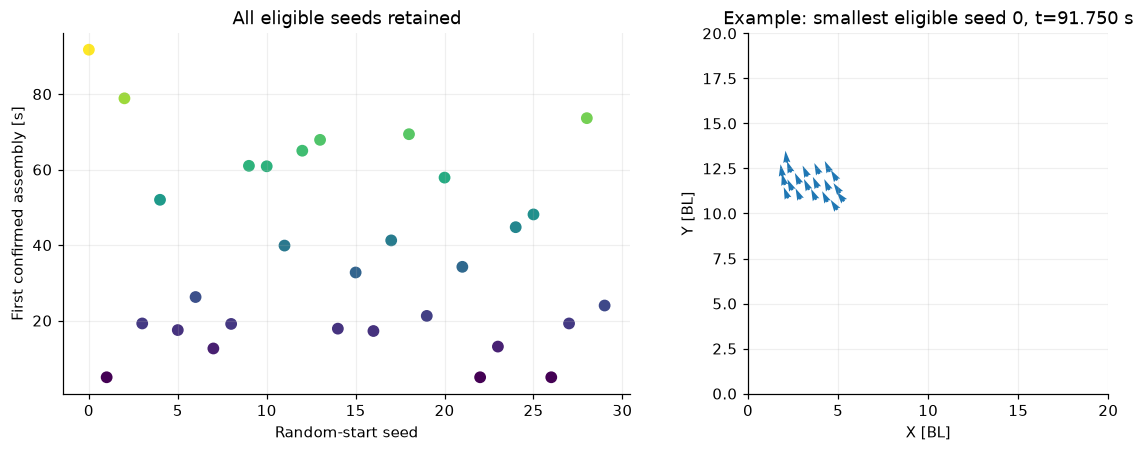

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].scatter(checkpoint_validation.Seed, checkpoint_validation.CheckpointTime_s,
                c=checkpoint_validation.AssemblyOnset_s, cmap="viridis", s=45)
axes[0].set(xlabel="Random-start seed", ylabel="First confirmed assembly [s]",
            title="All eligible seeds retained")
selected_seed = int(checkpoint_validation.sort_values("Seed").iloc[0].Seed)
example = json.loads((CHECKPOINT_DIR / f"seed_{selected_seed}.json").read_text())
positions, headings = np.asarray(example["positions"]), np.asarray(example["headings"])
axes[1].quiver(positions[:, 0], positions[:, 1], headings[:, 0], headings[:, 1],
               angles="xy", scale_units="xy", scale=1.5, color="tab:blue")
axes[1].set(xlabel="X [BL]", ylabel="Y [BL]", xlim=(0, example["model_parameters"]["width"]),
            ylim=(0, example["model_parameters"]["height"]), aspect="equal",
            title=f"Example: smallest eligible seed {selected_seed}, t={example['time']:.3f} s")
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(FIGURE_DIR / "04_assembled_checkpoints.png", dpi=160)
plt.show()

In [4]:
count = len(checkpoint_validation)
notes = f"""## Findings and use in a later experiment

**{count} assembled checkpoints** passed exact state/parameter/RNG round-trip checks, comparison with the original source continuation, and two identical constant-speed branch continuations. Checkpoints were taken at first confirmation, not chosen using later success or appearance.

A future paired experiment can load the same file twice, keep one branch as its constant-speed control, and introduce a local scalar-light response in the other branch. No such response is implemented here. The checkpoint does not include an artificial centroid force or overwrite random initialization: it records a state that the local social model reached from the original random start.

**Limits.** These checkpoints preserve **dt = 0.125 s, speed = 1 BL/s** and their full source parameters. They validate the save/reload infrastructure, not numerical safety at 5 BL/s. If notebook 02 requires a finer physical timestep, the final light study should generate and validate its assembled checkpoint cohort under that declared internal timestep. Silently altering the stored `dt` would make the original-continuation validation inapplicable. Future branch comparisons should also declare whether and how they synchronize stochastic streams once different conditions draw different numbers of random values.

The future sensing comparison will be conditional on successful assembly. The nonassembled, right-censored random-start runs remain part of the separate assembly question and must still be reported. A successful exact restart does not establish long-term stability or biological realism.
"""
display(Markdown(notes))
findings = {"validated_checkpoints": count,
            "all_state_roundtrips_exact": bool(checkpoint_validation.StateRoundTripExact.all()),
            "all_original_continuations_exact": bool(checkpoint_validation.OriginalContinuationExact.all()),
            "all_paired_controls_exact": bool(checkpoint_validation.PairedControlsExact.all()),
            "source_dt": sorted(checkpoint_validation.dt.unique().tolist()),
            "paired_control_updates": 64, "selection": "All first strict five-second confirmations",
            "light_implemented": False,
            "limitation": "Reference-dt checkpoint infrastructure; regenerate under a final validated numerical protocol."}
(DATA_DIR / "04_checkpoint_findings.json").write_text(json.dumps(findings, indent=2) + "\n")

## Findings and use in a later experiment

**30 assembled checkpoints** passed exact state/parameter/RNG round-trip checks, comparison with the original source continuation, and two identical constant-speed branch continuations. Checkpoints were taken at first confirmation, not chosen using later success or appearance.

A future paired experiment can load the same file twice, keep one branch as its constant-speed control, and introduce a local scalar-light response in the other branch. No such response is implemented here. The checkpoint does not include an artificial centroid force or overwrite random initialization: it records a state that the local social model reached from the original random start.

**Limits.** These checkpoints preserve **dt = 0.125 s, speed = 1 BL/s** and their full source parameters. They validate the save/reload infrastructure, not numerical safety at 5 BL/s. If notebook 02 requires a finer physical timestep, the final light study should generate and validate its assembled checkpoint cohort under that declared internal timestep. Silently altering the stored `dt` would make the original-continuation validation inapplicable. Future branch comparisons should also declare whether and how they synchronize stochastic streams once different conditions draw different numbers of random values.

The future sensing comparison will be conditional on successful assembly. The nonassembled, right-censored random-start runs remain part of the separate assembly question and must still be reported. A successful exact restart does not establish long-term stability or biological realism.


422

**Interpretation.** [Berdahl et al. (2013)](https://doi.org/10.1126/science.1225883) and [Puckett et al. (2018)](https://doi.org/10.1038/s41598-018-26037-9) motivate studying collective sensing in interacting schools. Our checkpoint-conditioning procedure is an experimental-design choice for controlled simulation comparisons, not a protocol attributed to either paper. The five-second persistence requirement is the diagnostic convention examined in notebook 03.